In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
%%bash
ls

drive
sample_data


In [4]:
%%bash
cd drive/MyDrive/'DH307 (1)'
ls

crop_six class_images
crop_six class_labels
labelled_images
MASK R-CNN.ipynb
test_practice


Shape of mask: torch.Size([7, 256, 256])


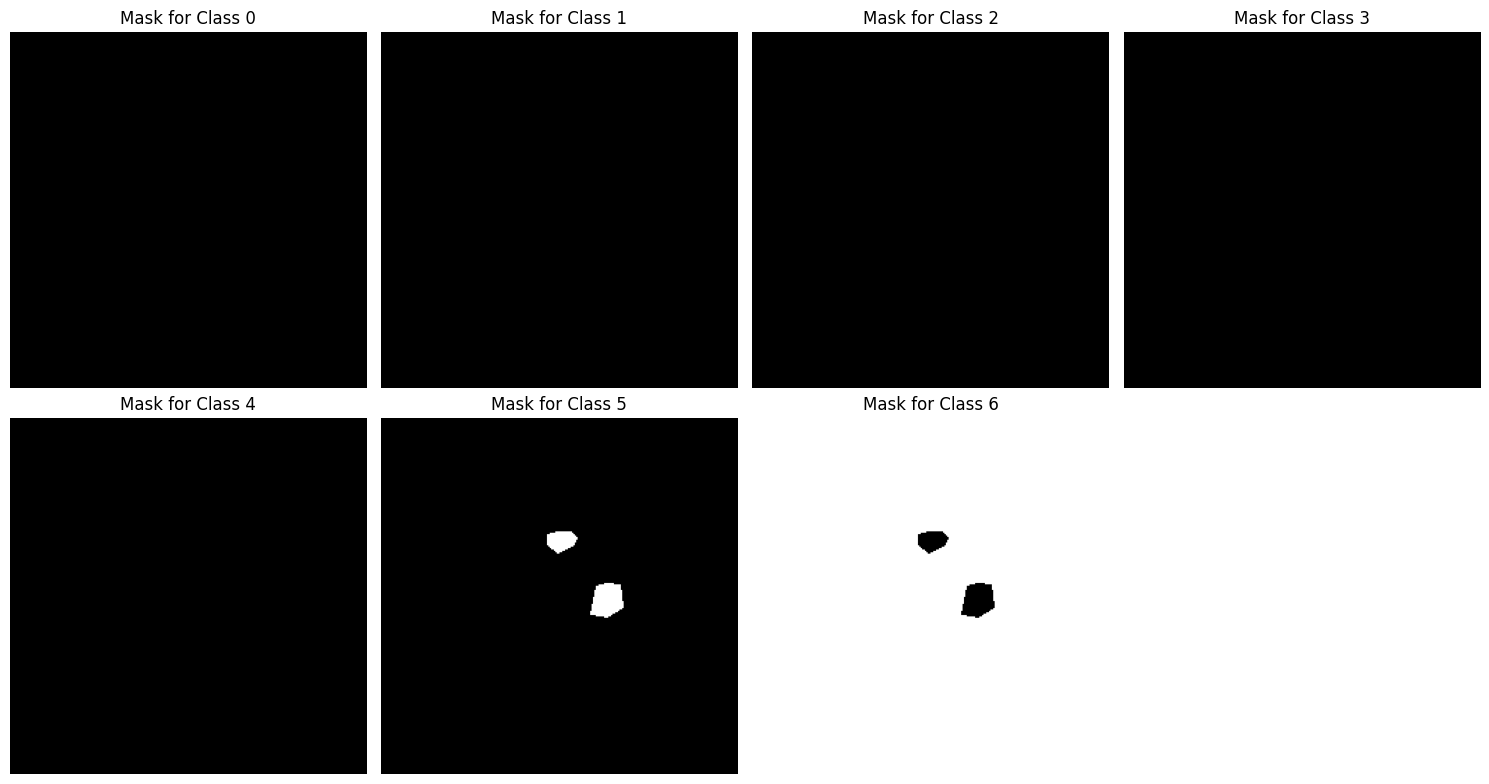

In [5]:
import os
import cv2
import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

class SegmentationDataset(Dataset):
    def __init__(self, image_dir, polygon_dir, num_classes, image_size=(256, 256), transform=None, target_transform=None):
        self.image_dir = image_dir
        self.polygon_dir = polygon_dir
        self.num_classes = num_classes  # Number of classes for one-hot encoding
        self.image_size = image_size  # Ensure consistent image size (e.g., 256x256)
        self.transform = transform
        self.target_transform = target_transform

        # Get list of all image files in the directory
        self.image_files = [
            f for f in os.listdir(image_dir)
            if f.endswith('.jpg') or f.endswith('.png')
        ]

    def __len__(self):
        return len(self.image_files)

    def load_polygon_coordinates(self, polygon_file):
      polygons = []
      classes = []
      with open(polygon_file, 'r') as file:
          for line in file:
              # Split the line and filter out any non-float elements
              coords = line.strip().split()
              class_label = int(coords[0])  # Directly convert to int
              classes.append(class_label)  # Append the single class label

              # Assuming the first element is the class label, skip it
              coords = list(map(float, coords[1:]))  # Convert to float

              # Convert to tuples of (x, y)
              poly = [(x, y) for x, y in zip(coords[0::2], coords[1::2])]
              polygons.append(poly)

      return polygons, classes

    def load_polygon_mask(self, image_file):
        mask_channel = np.zeros((self.num_classes, self.image_size[0], self.image_size[1]), dtype=np.float32)
        base_name = os.path.splitext(image_file)[0]
        polygon_path = os.path.join(self.polygon_dir, base_name + '.txt')

        if not os.path.exists(polygon_path):
            print(f"Warning: Mask file does not exist: {polygon_path}")
            return np.zeros(self.image_size, dtype=np.uint8)

        polygons, classes = self.load_polygon_coordinates(polygon_path)

        for poly, class_label in zip(polygons, classes):
            # Change this according to your class logic
            scaled_poly = [(int(x * self.image_size[0]), int(y * self.image_size[1])) for x, y in poly]
            # Here, class_label is now guaranteed to be an integer
            cv2.fillPoly(mask_channel[class_label], [np.array(scaled_poly, dtype=np.int32)], 1)

        mask_channel[6] = 1 - (mask_channel[0] + mask_channel[1] + mask_channel[2] + mask_channel[3] + mask_channel[4] + mask_channel[5])
        return mask_channel


    def one_hot_encode(self, mask):
        one_hot_mask = np.zeros((self.num_classes, self.image_size[0], self.image_size[1]), dtype=np.float32)
        for class_index in range(self.num_classes):
            one_hot_mask[class_index, :, :] = (mask == class_index).astype(np.float32)

        return one_hot_mask

    def __getitem__(self, idx):
        image_file = self.image_files[idx]
        image_path = os.path.join(self.image_dir, image_file)
        image = cv2.imread(image_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Resize image to consistent size (e.g., 256x256)
        image = cv2.resize(image, self.image_size)

        mask = self.load_polygon_mask(image_file)

        # Ensure the mask is correct before one-hot encoding
        # print(f"Loaded mask shape: {mask.shape}, dtype: {mask.dtype}")



        # Check the one-hot encoded mask shape
        # print(f"One-hot mask shape: {mask.shape}, dtype: {mask.dtype}")

        # Apply transformations
        if self.transform:
            image = self.transform(torch.from_numpy(image).permute(2, 0, 1).float())  # Convert to tensor and normalize

        if self.target_transform:
            mask_resized = np.zeros((self.num_classes, self.image_size[0], self.image_size[1]), dtype=np.float32)
            for i in range(self.num_classes):
                mask_resized[i, :, :] = cv2.resize(mask[i], self.image_size)  # Resize each channel of the mask
            mask = torch.tensor(mask_resized, dtype=torch.float32)

        # print(f"Final Image shape: {image.shape}, Final Mask shape: {mask.shape}")

        return image, mask


# Define transforms (using OpenCV where applicable)
image_transforms = transforms.Compose([
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normalize
])

# Mask transforms (use resizing with OpenCV)
mask_transforms = None  # Already handling resizing in __getitem__

# Initialize Dataset for all images
num_classes = 7  # Set to the number of classes in your segmentation task
full_dataset = SegmentationDataset(
    image_dir="/content/drive/MyDrive/DH307 (1)/crop_six class_images",
    polygon_dir="/content/drive/MyDrive/DH307 (1)/crop_six class_labels",
    num_classes=num_classes,
    image_size=(256, 256),  # Resize images and masks to 256x256
    transform=image_transforms,
    target_transform=mask_transforms
)

# Create a DataLoader for all images
data_loader = DataLoader(full_dataset, batch_size=4, shuffle=True, num_workers=2)

# Check if data is being loaded correctly
import matplotlib.pyplot as plt

# Assuming you have your data_loader defined and iterated through
import torch
import matplotlib.pyplot as plt

# Assuming you have your data_loader defined and iterated through
for images, masks in data_loader:
    # Print the shape of the mask for verification
    print("Shape of mask:", masks[3].shape)  # Should print torch.Size([num_classes, 256, 256])

    # Get the masks and convert them to NumPy arrays for plotting
    mask_to_plot = masks[0].cpu().detach().numpy()  # Ensure it's on CPU and detached from the graph

    # Plot all classes in a grid (2 rows, 4 columns for 7 classes)
    num_classes = mask_to_plot.shape[0]
    cols = 4  # Number of columns for the plot
    rows = (num_classes + cols - 1) // cols  # Calculate number of rows needed

    plt.figure(figsize=(15, 8))  # Adjust the figure size as needed

    for i in range(num_classes):
        selected_class_mask = mask_to_plot[i]  # Get the i-th class mask

        plt.subplot(rows, cols, i + 1)  # Create a subplot for each class
        plt.imshow(selected_class_mask, cmap='gray')
        plt.axis('off')  # Hide axes
        plt.title(f'Mask for Class {i}')  # Title based on class index

    plt.tight_layout()  # Adjust layout
    plt.show()

    break  # Stop after the first batch for visualization; remove this if you want to iterate through the entire dataset
 # Stop after the first batch for visualization; remove this if you want to iterate through the entire dataset
  # Stop after the first batch for visualizat # Remove this if you want to iterate through the entire dataset


In [6]:
import torch
from torch import nn
from torch.nn import functional as F
from torch.nn import init
def weights_init_normal(m):
    classname = m.__class__.__name__
    #print(classname)
    if classname.find('Conv') != -1:
        init.normal(m.weight.data, 0.0, 0.02)
    elif classname.find('Linear') != -1:
        init.normal(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        init.normal(m.weight.data, 1.0, 0.02)
        init.constant(m.bias.data, 0.0)


def weights_init_xavier(m):
    classname = m.__class__.__name__
    #print(classname)
    if classname.find('Conv') != -1:
        init.xavier_normal(m.weight.data, gain=1)
    elif classname.find('Linear') != -1:
        init.xavier_normal(m.weight.data, gain=1)
    elif classname.find('BatchNorm') != -1:
        init.normal(m.weight.data, 1.0, 0.02)
        init.constant(m.bias.data, 0.0)


def weights_init_kaiming(m):
    classname = m.__class__.__name__
    #print(classname)
    if classname.find('Conv') != -1:
        init.kaiming_normal(m.weight.data, a=0, mode='fan_in')
    elif classname.find('Linear') != -1:
        init.kaiming_normal(m.weight.data, a=0, mode='fan_in')
    elif classname.find('BatchNorm') != -1:
        init.normal(m.weight.data, 1.0, 0.02)
        init.constant(m.bias.data, 0.0)


def weights_init_orthogonal(m):
    classname = m.__class__.__name__
    #print(classname)
    if classname.find('Conv') != -1:
        init.orthogonal(m.weight.data, gain=1)
    elif classname.find('Linear') != -1:
        init.orthogonal(m.weight.data, gain=1)
    elif classname.find('BatchNorm') != -1:
        init.normal(m.weight.data, 1.0, 0.02)
        init.constant(m.bias.data, 0.0)


def init_weights(net, init_type='normal'):
    #print('initialization method [%s]' % init_type)
    if init_type == 'normal':
        net.apply(weights_init_normal)
    elif init_type == 'xavier':
        net.apply(weights_init_xavier)
    elif init_type == 'kaiming':
        net.apply(weights_init_kaiming)
    elif init_type == 'orthogonal':
        net.apply(weights_init_orthogonal)
    else:
        raise NotImplementedError('initialization method [%s] is not implemented' % init_type)

In [1]:
import torch
from torch import nn
from torch.nn import functional as F
class _GridAttentionBlockND(nn.Module):
    def __init__(self, in_channels, gating_channels, inter_channels=None, dimension=3, mode='concatenation',
                 sub_sample_factor=(2,2,2)):
        super(_GridAttentionBlockND, self).__init__()
        #what is concatnation
        assert dimension in [2, 3]
        assert mode in ['concatenation', 'concatenation_debug', 'concatenation_residual']
        # bro has also built for residual networks
        # Downsampling rate for the input featuremap
        if isinstance(sub_sample_factor, tuple): self.sub_sample_factor = sub_sample_factor
        elif isinstance(sub_sample_factor, list): self.sub_sample_factor = tuple(sub_sample_factor)
        else: self.sub_sample_factor = tuple([sub_sample_factor]) * dimension

        # Default parameter set
        self.mode = mode
        self.dimension = dimension
        self.sub_sample_kernel_size = self.sub_sample_factor

        # Number of channels (pixel dimensions)
        self.in_channels = in_channels
        self.gating_channels = gating_channels
        self.inter_channels = inter_channels

        if self.inter_channels is None:
            self.inter_channels = in_channels // 2
            if self.inter_channels == 0:
                self.inter_channels = 1

        if dimension == 3:
            conv_nd = nn.Conv3d
            bn = nn.BatchNorm3d
            self.upsample_mode = 'trilinear'
        elif dimension == 2:
            conv_nd = nn.Conv2d
            bn = nn.BatchNorm2d
            self.upsample_mode = 'bilinear'
        else:
            raise NotImplemented

        # Output transform
        self.W = nn.Sequential(
            conv_nd(in_channels=self.in_channels, out_channels=self.in_channels, kernel_size=1, stride=1, padding=0),
            bn(self.in_channels),
        )

        # Theta^T * x_ij + Phi^T * gating_signal + bias
        print(self.sub_sample_kernel_size)
        self.theta = conv_nd(in_channels=self.in_channels, out_channels=self.inter_channels,
                             kernel_size=self.sub_sample_kernel_size, stride=self.sub_sample_factor, padding=0, bias=False)
        self.phi = conv_nd(in_channels=self.gating_channels, out_channels=self.inter_channels,
                           kernel_size=1, stride=1, padding=0, bias=True)
        self.psi = conv_nd(in_channels=self.inter_channels, out_channels=1, kernel_size=1, stride=1, padding=0, bias=True)

        # Initialise weights
        for m in self.children():
            init_weights(m, init_type='kaiming')

        # Define the operation
        if mode == 'concatenation':
            self.operation_function = self._concatenation
        elif mode == 'concatenation_debug':
            self.operation_function = self._concatenation_debug
        elif mode == 'concatenation_residual':
            self.operation_function = self._concatenation_residual
        else:
            raise NotImplementedError('Unknown operation function.')


    def forward(self, x, g):
        '''
        :param x: (b, c, t, h, w)
        :param g: (b, g_d)
        :return:
        '''

        output = self.operation_function(x, g)
        return output

    def _concatenation(self, x, g):
        input_size = x.size()
        batch_size = input_size[0]
        assert batch_size == g.size(0)

        # theta => (b, c, t, h, w) -> (b, i_c, t, h, w) -> (b, i_c, thw)
        # phi   => (b, g_d) -> (b, i_c)
        theta_x = self.theta(x)
        theta_x_size = theta_x.size()

        # g (b, c, t', h', w') -> phi_g (b, i_c, t', h', w')
        #  Relu(theta_x + phi_g + bias) -> f = (b, i_c, thw) -> (b, i_c, t/s1, h/s2, w/s3)
        phi_g = F.upsample(self.phi(g), size=theta_x_size[2:], mode=self.upsample_mode)
        f = F.relu(theta_x + phi_g, inplace=True)

        #  psi^T * f -> (b, psi_i_c, t/s1, h/s2, w/s3)
        sigm_psi_f = F.sigmoid(self.psi(f))

        # upsample the attentions and multiply
        sigm_psi_f = F.upsample(sigm_psi_f, size=input_size[2:], mode=self.upsample_mode)
        y = sigm_psi_f.expand_as(x) * x
        W_y = self.W(y)

        return W_y, sigm_psi_f

    def _concatenation_debug(self, x, g):
        input_size = x.size()
        batch_size = input_size[0]
        assert batch_size == g.size(0)

        # theta => (b, c, t, h, w) -> (b, i_c, t, h, w) -> (b, i_c, thw)
        # phi   => (b, g_d) -> (b, i_c)
        theta_x = self.theta(x)
        theta_x_size = theta_x.size()

        # g (b, c, t', h', w') -> phi_g (b, i_c, t', h', w')
        #  Relu(theta_x + phi_g + bias) -> f = (b, i_c, thw) -> (b, i_c, t/s1, h/s2, w/s3)
        phi_g = F.upsample(self.phi(g), size=theta_x_size[2:], mode=self.upsample_mode)
        f = F.softplus(theta_x + phi_g)

        #  psi^T * f -> (b, psi_i_c, t/s1, h/s2, w/s3)
        sigm_psi_f = F.sigmoid(self.psi(f))

        # upsample the attentions and multiply
        sigm_psi_f = F.upsample(sigm_psi_f, size=input_size[2:], mode=self.upsample_mode)
        y = sigm_psi_f.expand_as(x) * x
        W_y = self.W(y)

        return W_y, sigm_psi_f


    def _concatenation_residual(self, x, g):
        input_size = x.size()
        batch_size = input_size[0]
        assert batch_size == g.size(0)

        # theta => (b, c, t, h, w) -> (b, i_c, t, h, w) -> (b, i_c, thw)
        # phi   => (b, g_d) -> (b, i_c)
        theta_x = self.theta(x)
        theta_x_size = theta_x.size()

        # g (b, c, t', h', w') -> phi_g (b, i_c, t', h', w')
        #  Relu(theta_x + phi_g + bias) -> f = (b, i_c, thw) -> (b, i_c, t/s1, h/s2, w/s3)
        # print(theta_x_)
        phi_g = F.upsample(self.phi(g), size=theta_x_size[2:], mode=self.upsample_mode)
        f = F.relu(theta_x + phi_g, inplace=True)

        #  psi^T * f -> (b, psi_i_c, t/s1, h/s2, w/s3)
        f = self.psi(f).view(batch_size, 1, -1)
        sigm_psi_f = F.softmax(f, dim=2).view(batch_size, 1, *theta_x.size()[2:])

        # upsample the attentions and multiply
        sigm_psi_f = F.upsample(sigm_psi_f, size=input_size[2:], mode=self.upsample_mode)
        y = sigm_psi_f.expand_as(x) * x
        W_y = self.W(y)

        return W_y, sigm_psi_f


class GridAttentionBlock2D(_GridAttentionBlockND):
    def __init__(self, in_channels, gating_channels, inter_channels=None, mode='concatenation',
                 sub_sample_factor=(2,2,2)):
        super(GridAttentionBlock2D, self).__init__(in_channels,
                                                   inter_channels=inter_channels,
                                                   gating_channels=gating_channels,
                                                   dimension=2, mode=mode,
                                                   sub_sample_factor=sub_sample_factor,
                                                   )

In [7]:
import torch.nn as nn

import torch.nn.functional as F
# from models.layers.grid_attention_layer import GridAttentionBlock2D
# from models.networks_other import init_weights
class unetConv2(nn.Module):
    def __init__(self, in_size, out_size, is_batchnorm, n=2, ks=3, stride=1, padding=1):
        super(unetConv2, self).__init__()
        self.n = n
        self.ks = ks
        self.stride = stride
        self.padding = padding
        s = stride
        p = padding
        if is_batchnorm:
            for i in range(1, n+1):
                conv = nn.Sequential(nn.Conv2d(in_size, out_size, ks, s, p),
                                     nn.BatchNorm2d(out_size),
                                     nn.ReLU(inplace=True),)
                setattr(self, 'conv%d'%i, conv)
                in_size = out_size

        else:
            for i in range(1, n+1):
                conv = nn.Sequential(nn.Conv2d(in_size, out_size, ks, s, p),
                                     nn.ReLU(inplace=True),)
                setattr(self, 'conv%d'%i, conv)
                in_size = out_size

        # initialise the blocks
        for m in self.children():
            init_weights(m, init_type='kaiming')

    def forward(self, inputs):
        x = inputs
        for i in range(1, self.n+1):
            conv = getattr(self, 'conv%d'%i)
            x = conv(x)

        return x
class unetUp(nn.Module):
    def __init__(self, in_size, out_size, is_deconv):
        super(unetUp, self).__init__()
        self.conv = unetConv2(in_size, out_size, False)
        if is_deconv:
            self.up = nn.ConvTranspose2d(in_size, out_size, kernel_size=4, stride=2, padding=1)
        else:
            self.up = nn.UpsamplingBilinear2d(scale_factor=2)

        # initialise the blocks
        for m in self.children():
            if m.__class__.__name__.find('unetConv2') != -1: continue
            init_weights(m, init_type='kaiming')

    def forward(self, inputs1, inputs2):
        outputs2 = self.up(inputs2)
        offset = outputs2.size()[2] - inputs1.size()[2]
        padding = 2 * [offset // 2, offset // 2]
        outputs1 = F.pad(inputs1, padding)
        return self.conv(torch.cat([outputs1, outputs2], 1))


class UnetGridGatingSignal2(nn.Module):
    def __init__(self, in_size, out_size, kernel_size=(1,1), is_batchnorm=True):
        super(UnetGridGatingSignal2, self).__init__()

        if is_batchnorm:
            self.conv1 = nn.Sequential(nn.Conv2d(in_size, out_size, kernel_size, (1,1), (0, 0)),
                                       nn.BatchNorm2d(out_size),
                                       nn.ReLU(inplace=True),
                                       )
        else:
            self.conv1 = nn.Sequential(nn.Conv2d(in_size, out_size, kernel_size, (1,1), (0,0)),
                                       nn.ReLU(inplace=True),
                                       )

        # initialise the blocks
        for m in self.children():
            init_weights(m, init_type='kaiming')

    def forward(self, inputs):
        outputs = self.conv1(inputs)
        return outputs


class unet_grid_attention_2D(nn.Module):

    def __init__(self, feature_scale=4, n_classes=7, is_deconv=True, in_channels=3,
                 nonlocal_mode='concatenation', attention_dsample=(2,2), is_batchnorm=True):
        super(unet_grid_attention_2D, self).__init__()
        self.is_deconv = is_deconv
        self.in_channels = in_channels
        self.is_batchnorm = is_batchnorm
        self.feature_scale = feature_scale

        filters = [64, 128, 256, 512, 1024]
        filters = [int(x / self.feature_scale) for x in filters]

        # downsampling
        self.conv1 = unetConv2(self.in_channels, filters[0], self.is_batchnorm)
        self.maxpool1 = nn.MaxPool2d(kernel_size=(2, 2))

        self.conv2 = unetConv2(filters[0], filters[1], self.is_batchnorm)
        self.maxpool2 = nn.MaxPool2d(kernel_size=(2, 2))

        self.conv3 = unetConv2(filters[1], filters[2], self.is_batchnorm)
        self.maxpool3 = nn.MaxPool2d(kernel_size=(2, 2))

        self.conv4 = unetConv2(filters[2], filters[3], self.is_batchnorm)
        self.maxpool4 = nn.MaxPool2d(kernel_size=(2, 2))

        self.center = unetConv2(filters[3], filters[4], self.is_batchnorm)
        self.gating = UnetGridGatingSignal2(filters[4], filters[3], kernel_size=(1, 1), is_batchnorm=self.is_batchnorm)

        # attention blocks
        self.attentionblock2 = GridAttentionBlock2D(in_channels=filters[1], gating_channels=filters[3],
                                                    inter_channels=filters[1], sub_sample_factor=attention_dsample, mode=nonlocal_mode)
        self.attentionblock3 = GridAttentionBlock2D(in_channels=filters[2], gating_channels=filters[3],
                                                    inter_channels=filters[2], sub_sample_factor=attention_dsample, mode=nonlocal_mode)
        self.attentionblock4 = GridAttentionBlock2D(in_channels=filters[3], gating_channels=filters[3],
                                                    inter_channels=filters[3], sub_sample_factor=attention_dsample, mode=nonlocal_mode)

        # upsampling
        self.up_concat4 = unetUp(filters[4], filters[3], self.is_deconv)
        self.up_concat3 = unetUp(filters[3], filters[2], self.is_deconv)
        self.up_concat2 = unetUp(filters[2], filters[1], self.is_deconv)
        self.up_concat1 = unetUp(filters[1], filters[0], self.is_deconv)

        # final conv (without any concat)
        self.final = nn.Conv2d(filters[0], n_classes, 1)

        # initialise weights
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                init_weights(m, init_type='kaiming')
            elif isinstance(m, nn.BatchNorm2d):
                init_weights(m, init_type='kaiming')

    def forward(self, inputs):
        # Feature Extraction
        conv1 = self.conv1(inputs)
        maxpool1 = self.maxpool1(conv1)

        conv2 = self.conv2(maxpool1)
        maxpool2 = self.maxpool2(conv2)

        conv3 = self.conv3(maxpool2)
        maxpool3 = self.maxpool3(conv3)

        conv4 = self.conv4(maxpool3)
        maxpool4 = self.maxpool4(conv4)

        # Gating Signal Generation
        center = self.center(maxpool4)
        gating = self.gating(center)

        # Attention Mechanism
        g_conv4, att4 = self.attentionblock4(conv4, gating)
        g_conv3, att3 = self.attentionblock3(conv3, gating)
        g_conv2, att2 = self.attentionblock2(conv2, gating)
        # print(att2.max())
        # Upscaling Part (Decoder)
        up4 = self.up_concat4(g_conv4, center)
        up3 = self.up_concat3(g_conv3, up4)
        up2 = self.up_concat2(g_conv2, up3)
        up1 = self.up_concat1(conv1, up2)

        final = self.final(up1)
        return final

    @staticmethod
    def apply_argmax_softmax(pred):
        log_p = F.softmax(pred, dim=1)

        return log_p


In [8]:
def dice_coef(y_true, y_pred):
    y_true_f = y_true.flatten()
    y_pred_f = y_pred.flatten()
    intersection = torch.sum(y_true_f * y_pred_f)
    return (2.0 * intersection + 1.0) / (torch.sum(y_true_f) + torch.sum(y_pred_f) + 1.0)


def jacard_coef(y_true, y_pred):
    # print(y_true.shape)
    # print(y_pred.shape)
    y_true_f = y_true.flatten()
    y_pred_f = y_pred.flatten()
    intersection = torch.sum(y_true_f * y_pred_f)
    return (intersection + 1.0) / (torch.sum(y_true_f) + torch.sum(y_pred_f) - intersection + 1.0)


def jacard_coef_loss(y_true, y_pred):
    return -jacard_coef(y_true, y_pred)


def dice_coef_loss(y_true, y_pred):
    return -dice_coef(y_true, y_pred)

In [10]:
!pip install segmentation_models_pytorch
from segmentation_models_pytorch import losses
FocalLoss = losses.FocalLoss(mode="multilabel")

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 kB 3.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 109.5/109.5 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 29.7 MB/s eta 0:00:00
  Created wheel for efficientnet-pytorch: filename=efficientnet_pytorch-0.7.1-py3-none-any.whl size=16425 sha256=197d34887513aaa86903add0a7a63da2c42e9548d2685fd62f7c3970ff49d545
  Stored in directory: /root/.cache/pip/wheels/03/3f/e9/911b1bc46869644912bda90a56bcf7b960f20b5187feea3baf
  Created wheel for pretrainedmodels: filename=pretrainedmodels-0.7.4-py3-none-any.whl size=60944 sha256=380363d826d475bcf015840951a3051e2ad4f60263628cd831d6419afd4859c7
  Stored in directory: /root/.cache/pip/wheels/35/cb/a5/8f534c60142835bfc889f9a482e4a67e0b817032d9c6883b64
Successfully built efficientnet-pytorch

In [ ]:
import torch.optim as optim
from tqdm import tqdm

# Assuming your model, dataloader, and device are already defined
device  = 'cpu'
model = unet_grid_attention_2D()  # Instantiate your model
model.to(device)  # Move to the appropriate device
optimizer = optim.Adam(model.parameters(), lr=0.001)  # Choose an optimizer

# Training Loop
num_epochs = 20  # Set number of epochs

for epoch in range(num_epochs):
    model.train()  # Set model to training mode
    running_loss = 0.0
    running_iou = 0.0

    for images, masks in tqdm(data_loader):
        # print(images)
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()  # Zero the gradients

        outputs = model(images)  # Forward pass
        outputs = F.softmax(outputs, dim=1)  # Apply softmax to get probabilities
        # print("Hello")
        # print(masks.shape, outputs.shape)
        # print("Hello")
        # Compute Dice loss
        loss = FocalLoss(outputs, masks)
        running_loss += loss.item()

        # Compute Jaccard coefficient
        iou = jacard_coef(outputs, masks)  # Get predicted class
        running_iou += iou.item()
        print(loss)
        loss.backward()  # Backward pass
        optimizer.step()  # Optimize

    avg_loss = running_loss / len(data_loader)
    avg_iou = running_iou / len(data_loader)

    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}, Jaccard Coefficient: {avg_iou:.4f}')


<ipython-input-6-40e0db2c2403>:33: FutureWarning: `nn.init.kaiming_normal` is now deprecated in favor of `nn.init.kaiming_normal_`.
  init.kaiming_normal(m.weight.data, a=0, mode='fan_in')
<ipython-input-6-40e0db2c2403>:37: FutureWarning: `nn.init.normal` is now deprecated in favor of `nn.init.normal_`.
  init.normal(m.weight.data, 1.0, 0.02)
<ipython-input-6-40e0db2c2403>:38: FutureWarning: `nn.init.constant` is now deprecated in favor of `nn.init.constant_`.
  init.constant(m.bias.data, 0.0)


(2, 2)
(2, 2)
(2, 2)


  0%|          | 0/219 [00:00<?, ?it/s]<ipython-input-1-da3264ac3629>:94: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  phi_g = F.upsample(self.phi(g), size=theta_x_size[2:], mode=self.upsample_mode)
<ipython-input-1-da3264ac3629>:101: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  sigm_psi_f = F.upsample(sigm_psi_f, size=input_size[2:], mode=self.upsample_mode)


tensor(0.2191, grad_fn=<MeanBackward0>)


  0%|          | 1/219 [00:09<33:50,  9.31s/it]

tensor(0.2126, grad_fn=<MeanBackward0>)


... (16 outputs left out)

  5%|▍         | 10/219 [00:35<11:10,  3.21s/it]

tensor(0.1563, grad_fn=<MeanBackward0>)


  5%|▌         | 11/219 [00:42<15:35,  4.50s/it]

tensor(0.1558, grad_fn=<MeanBackward0>)


In [ ]:
import torch
from tqdm import tqdm

def test_model(model, test_loader, device):
    model.eval()  # Set the model to evaluation mode
    running_iou = 0.0
    total_batches = 0

    with torch.no_grad():  # No need to calculate gradients during testing
        for images, masks in tqdm(test_loader):
            images = images.to(device)
            masks = masks.to(device)

            # Forward pass (no need for backward or optimization)
            outputs = model(images)

            # Predicted class is the argmax across the channel dimension (num_classes)
            predicted_classes = outputs.argmax(dim=1)  # Shape: [batch_size, height, width]
            true_classes = masks.argmax(dim=1)         # Shape: [batch_size, height, width]

            # Compute IoU for the batch
            iou = jacard_coef(predicted_classes, true_classes)
            running_iou += iou.item()
            total_batches += 1

    # Calculate the mean IoU across all batches
    avg_iou = running_iou / total_batches
    print(f"Average IoU on test set: {avg_iou:.4f}")
    return avg_iou

# Load your trained model (if saved)
# Example: model.load_state_dict(torch.load('model_checkpoint.pth'))

# Assuming you have a test DataLoader named `test_loader`:
test_loader = DataLoader(full_dataset, batch_size=4, shuffle=False, num_workers=2)

# Set the device to GPU if available, otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Test the model on the test set
avg_iou = test_model(model, test_loader, device)
